# ДЗ по BCR (MiXCR + repseq)

Образец: `DChu_T7_pbmc_d7COVID2_2` (PBMC, 7-й день после COVID-19).
Риды собраны в MiXCR 4.7.0 (`generic-amplicon`, `--species hsa --rna --floating-left-alignment-boundary --floating-right-alignment-boundary C --assemble-clonotypes-by CDR3`). По QC выровнялось 93.08% ридов, off-target 0.1%, на выходе таблица по тяжёлой цепи `IGH`.

Семинарский ноутбук сделан под 30 образцов TCR, а тут один образец BCR, поэтому межгрупповые графики, F2 и MDS не имеют смысла

In [1]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import repseq
from repseq import clonosets as cl, clone_filter as clf, stats, plot as rsplot

stats.AA_PROPS_PATH = os.path.join(os.path.dirname(repseq.__file__), "resourses", "aa_property_table.txt")

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").is_file())
bcr_clonosets = cl.find_all_mixcr_clonosets(str(PROJECT_ROOT / "outputs" / "bcr_mixcr"), show_offtarget=False, offtarget_threshold=0.01)

# UMI-колонки нет, считаем по ридам
func_filter = clf.Filter(functionality="f", by_umi=False)
ds_filter = clf.Filter(functionality="f", downsample=50000, by_umi=False, seed=100)
bcr_clonosets

,sample_id,chain,filename
0,DChu_T7_pbmc_d7COVID2_2,IGH,/home/STUDY/FBMF/studfbmf02_13/Bioinformatics-...


## Статистика клоносета

In [2]:
bcr_stats = stats.calc_clonoset_stats(bcr_clonosets, cpu=2)
bcr_stats[["sample_id", "chain", "clones", "clones_func", "clones_nonfunc_freq", "reads", "reads_func"]]

Using 2 cores


CalcClonosetStats |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,clones,clones_func,clones_nonfunc_freq,reads,reads_func
0,DChu_T7_pbmc_d7COVID2_2,IGH,49079,46795,0.046537,771566,760664


## Свойства и длины CDR3

In [3]:
bcr_cdr3_props = stats.calc_cdr3_properties(bcr_clonosets, cl_filter=func_filter, cpu=2)
bcr_cdr3_props[["sample_id", "mean_cdr3nt_len", "mean_insert_size", "zero_insert_freq", "cdr3_full_hydropathy", "cdr3_full_charge"]]

Using 2 cores


CalcCDR3aaProperties |##################################################| 1/1 calcultaion(s) processed


,sample_id,mean_cdr3nt_len,mean_insert_size,zero_insert_freq,cdr3_full_hydropathy,cdr3_full_charge
0,DChu_T7_pbmc_d7COVID2_2,53.707874,12.652246,0.011585,-6.119094,-0.116383


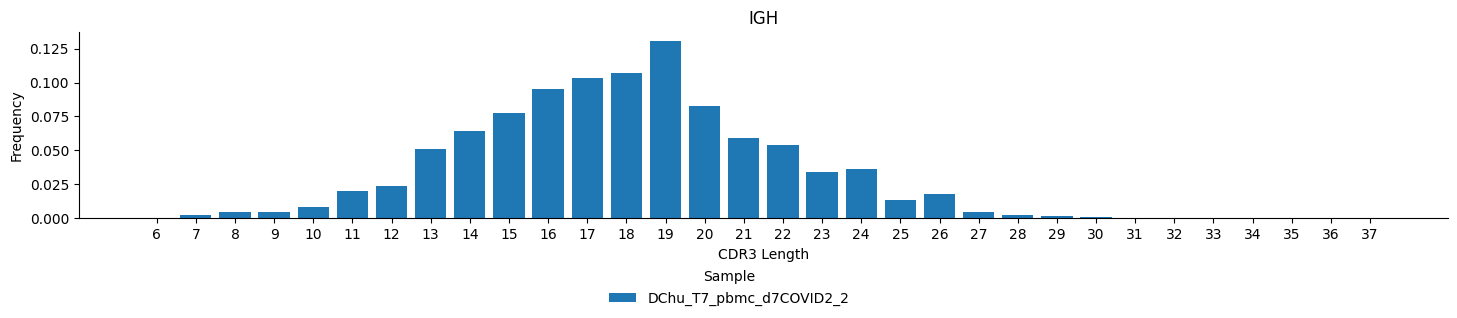

In [4]:
bcr_len_dist = stats.cdr3_length_distributions(
    bcr_clonosets, cl_filter=func_filter, cpu=2,
    count_by_freq=True, seq_type="aa", table="long", zero_fill=True, verbose=False
)
rsplot.cdr3_length_distributions(bcr_len_dist)

## Разнообразие, конвергенция и rarefaction

In [5]:
display(stats.calc_diversity_stats(bcr_clonosets, cl_filter=ds_filter, cpu=2))
display(stats.calc_convergence(bcr_clonosets, cl_filter=ds_filter, cpu=2))

CalcDiversityStats settings: seed=None, downsample=50000, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores


CalcClonosetStats |##################################################| 1/1 calcultaion(s) processed
WARNING! Random filter is applied, but random seed is not set. This may lead to non-reproducible results.
You may set the seed (of any hashable type) by specifying 'seed='
Using 2 cores


CalcDiversityStats |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,diversity,norm_shannon_wiener,clonality,shannon_wiener,chao1,richness,ace,goods_coverage,d50,simpson,inverse_simpson,gini_simpson,berger_parker,gini_coefficient
0,DChu_T7_pbmc_d7COVID2_2,IGH,19195.0,0.90201,0.09799,8.895987,34582.182641,19195.0,38240.984526,0.76968,0.091482,0.000782,1277.97487,0.999218,0.0161,0.532794


CalcConvergence settings: seed=None, downsample=50000, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores


CalcClonosetStats |##################################################| 1/1 calcultaion(s) processed
WARNING! Random filter is applied, but random seed is not set. This may lead to non-reproducible results.
You may set the seed (of any hashable type) by specifying 'seed='
Using 2 cores


CalcConvergence |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,convergence,convergence_v,convergence_vj
0,DChu_T7_pbmc_d7COVID2_2,IGH,1.018248,1.018032,1.017924


Using 2 cores


CalcRarefactionPoints |##################################################| 1/1 calcultaion(s) processed


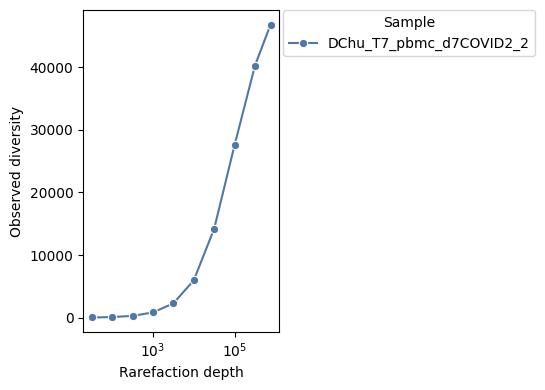

In [6]:
bcr_rare = stats.calc_rarefaction_curve(bcr_clonosets, cl_filter=func_filter, cpu=2)
rsplot.rarefaction_curve(bcr_rare)

## Топ-клоны, V-сегменты и изотипы

In [7]:
raw_bcr = pd.read_csv(bcr_clonosets.loc[0, "filename"], sep="\t")
raw_bcr["topV"] = raw_bcr["allVHitsWithScore"].astype(str).str.split("*").str[0]
raw_bcr["isotype"] = raw_bcr["allCHitsWithScore"].astype(str).str.split("*").str[0].str.replace("nan", "Unknown")

raw_bcr[["cloneId", "readCount", "readFraction", "aaSeqCDR3", "allVHitsWithScore", "allCHitsWithScore"]].head(10)

,cloneId,readCount,readFraction,aaSeqCDR3,allVHitsWithScore,allCHitsWithScore
0,0,12553.0,0.016270,CARDRRTGLWSGYGYMDVW,IGHV3-33*00(1954.4),IGHG3*00(409.2)
1,1,4418.0,0.005726,CARDPNYDFWSGGDMNVW,IGHV3-21*00(2303.6),IGHM*00(377.4)
2,2,4347.0,0.005634,CARSDMLRFVEWTGSYQRFHMDVW,IGHV4-61*00(1119.7),IGHA1*00(486.9)
3,3,4049.0,0.005248,CAHSPASQGHFLMTFGGLIIPHFDSW,IGHV2-5*00(2043.7),IGHM*00(470.7)
4,4,3512.0,0.004552,CARDRRTGIWSGYGYMDVW,IGHV3-33*00(1968.9),IGHG1*00(368.5)
5,5,3291.0,0.004265,CARGGDPRVVVAATDAFDFW,IGHV1-46*00(1736.1),IGHA1*00(485.9)
6,6,2881.0,0.003734,CAHRPGIALVGAGAFRFDPW,IGHV2-5*00(1914.1),IGHA2*00(388.1)
7,7,2795.0,0.003623,CARRERFWSGYYTGREMIAFDIW,IGHV1-18*00(1952.5),IGHM*00(399.2)
8,8,2697.0,0.003495,CAHSSDIIGGSWGFGMDVW,IGHV2-5*00(2042.7),IGHG1*00(479.2)
9,9,2631.0,0.003410,CTTDLDYYDSSGYRFDCW,IGHV3-15*00(2161.6),IGHM*00(470.8)


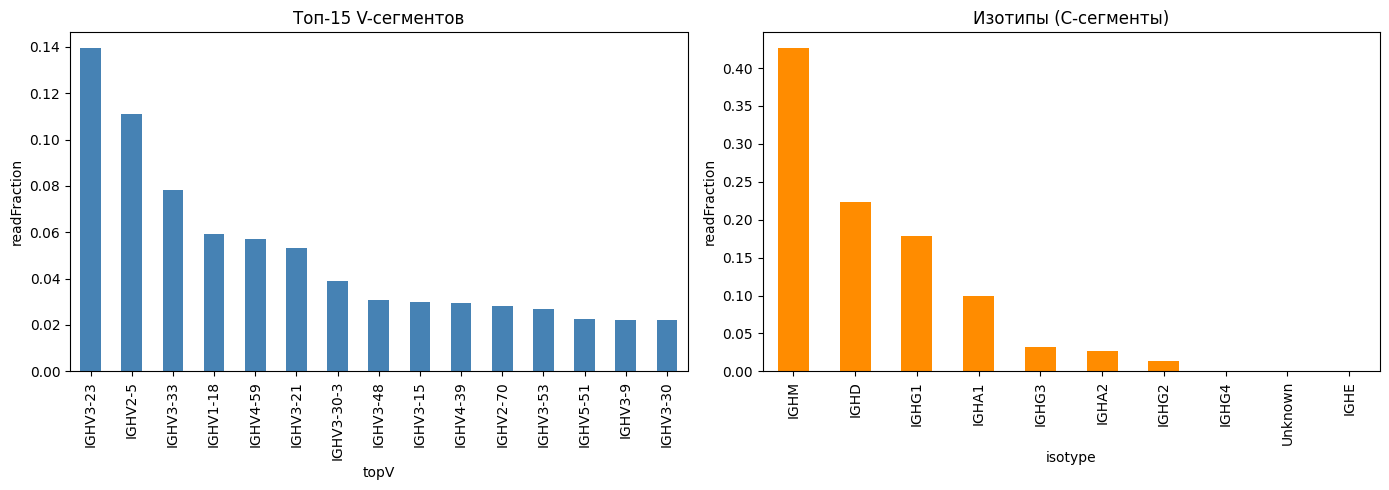

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
raw_bcr.groupby("topV")["readFraction"].sum().sort_values(ascending=False).head(15).plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Топ-15 V-сегментов")
axes[0].set_ylabel("readFraction")

raw_bcr.groupby("isotype")["readFraction"].sum().sort_values(ascending=False).plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set_title("Изотипы (C-сегменты)")
axes[1].set_ylabel("readFraction")
plt.tight_layout()
plt.show()

## Кратко по результатам

- Глубина хорошая: 760 664 функциональных ридов и 46 795 функциональных клонотипов `IGH`, нефункциональных всего 4.65%.
- Средняя длина CDR3 заметно больше, чем у TCR из прошлого ноутбука (~53.7 nt, около 18 aa), и распределение шире, что типично для тяжёлой цепи антител.
- Есть явная клональная экспансия (верхний клон забирает 1.63% всех ридов), что ожидаемо для 7-го дня после COVID-19.
- В топ-10 сразу видна проблема переноса TCR-пайплайна на BCR: клон 0 (`CARDRRTGLWSGYGYMDVW`, `IGHV3-33`, `IGHG3`) и клон 4 (`CARDRRTGIWSGYGYMDVW`, `IGHV3-33`, `IGHG1`) отличаются ровно на одну аминокислоту (`L` -> `I`) и имеют разные изотипы. По факту это потомки одного B-клеточного клона после соматической гипермутации и переключения класса, но при сборке по точному CDR3 они считаются как два разных клонотипа. Для нормального анализа BCR нужно собирать полные VDJ и строить деревья клонов.